In [27]:
# ── Librerías ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import janitor
import sqlalchemy as sa
import os
from pathlib import Path
from dotenv import load_dotenv

%matplotlib inline
# ── Librerías ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import janitor
import sqlalchemy as sa
import os
from pathlib import Path
from dotenv import load_dotenv

%matplotlib inline

# ── Opciones de visualización ─────────────────────────────────────────
# Desactivar notación científica
pd.set_option('display.float_format', '{:.3f}'.format)
np.set_printoptions(suppress=True)

# Ver todas las columnas al imprimir un DataFrame
pd.set_option('display.max_columns', None)

# ── Rutas del proyecto ────────────────────────────────────────────────
# Se resuelven desde la ubicación del notebook, así funcionan
# igual en cualquier máquina
RAIZ = Path.cwd().parent

ORIGINALES   = RAIZ / '02_datos' / '01_Originales'
VALIDACION   = RAIZ / '02_datos' / '02_Validacion'
ENTRENAMIENTO = RAIZ / '02_datos' / '03_Entrenamiento'
CACHES       = RAIZ / '02_datos' / '04_Caches'
MODELOS      = RAIZ / '05_modelos'
RESULTADOS   = RAIZ / '06_resultados'

# ── Variables de entorno ──────────────────────────────────────────────
load_dotenv(RAIZ / '.env')

print('✅ Entorno listo')
print(f'   Raíz del proyecto: {RAIZ}')

✅ Entorno listo
   Raíz del proyecto: c:\Users\Admin\Desktop\Desktop\CarpetaFisica\Data Detective\Mis Casos(Importante)\PROYECTO 5 - FORECASTING RETAIL\02_FORECASTING


In [28]:
cat = pd.read_pickle(ENTRENAMIENTO/'cat_resultado_calidad.pkl')
num = pd.read_pickle(ENTRENAMIENTO/'num_resultado_calidad.pkl')

## EDA CATEGORICAS

### Analisis estadistico

In [29]:
cat.columns.tolist()

['store_id',
 'item_id',
 'dia_ind',
 'year',
 'month',
 'wday',
 'weekday',
 'event_name_1',
 'event_type_1']

In [30]:
incluir = cat.columns.tolist()
del incluir[2]

In [31]:
def frecuencias_cat(df_cat):
    largo = df_cat.astype(str).melt(var_name='variable', value_name='Valor')
    resultado = largo.groupby('variable')['Valor'].value_counts(normalize=True).rename('Frecuencia').reset_index()
    return resultado.sort_values(['variable', 'Frecuencia'], ascending=False).reset_index(drop=True)

In [32]:
pd.set_option('display.max_rows', None)
frecuencias_cat(cat[incluir])

,variable,Valor,Frecuencia
0,year,2014,0.344
1,year,2013,0.341
2,year,2015,0.315
3,weekday,Sunday,0.143
4,weekday,Monday,0.143
5,weekday,Saturday,0.143
6,weekday,Tuesday,0.143
7,weekday,Wednesday,0.143
8,weekday,Thursday,0.143
9,weekday,Friday,0.143


In [33]:
def graficos_eda_categoricos(cat):
    # ── Calculamos el número de filas que necesitamos ─────────────────
    from math import ceil
    filas = ceil(cat.shape[1] / 2)

    # ── Definimos el gráfico ──────────────────────────────────────────
    f, ax = plt.subplots(nrows=filas, ncols=2, figsize=(16, filas * 6))

    # ── Aplanamos para iterar por el gráfico como 1 dimensión ─────────
    ax = ax.flat

    # ── Bucle que va añadiendo gráficos ───────────────────────────────
    for cada, variable in enumerate(cat):
        cat[variable].value_counts().plot.barh(ax=ax[cada])
        ax[cada].set_title(variable, fontsize=12, fontweight="bold")
        ax[cada].tick_params(labelsize=12)

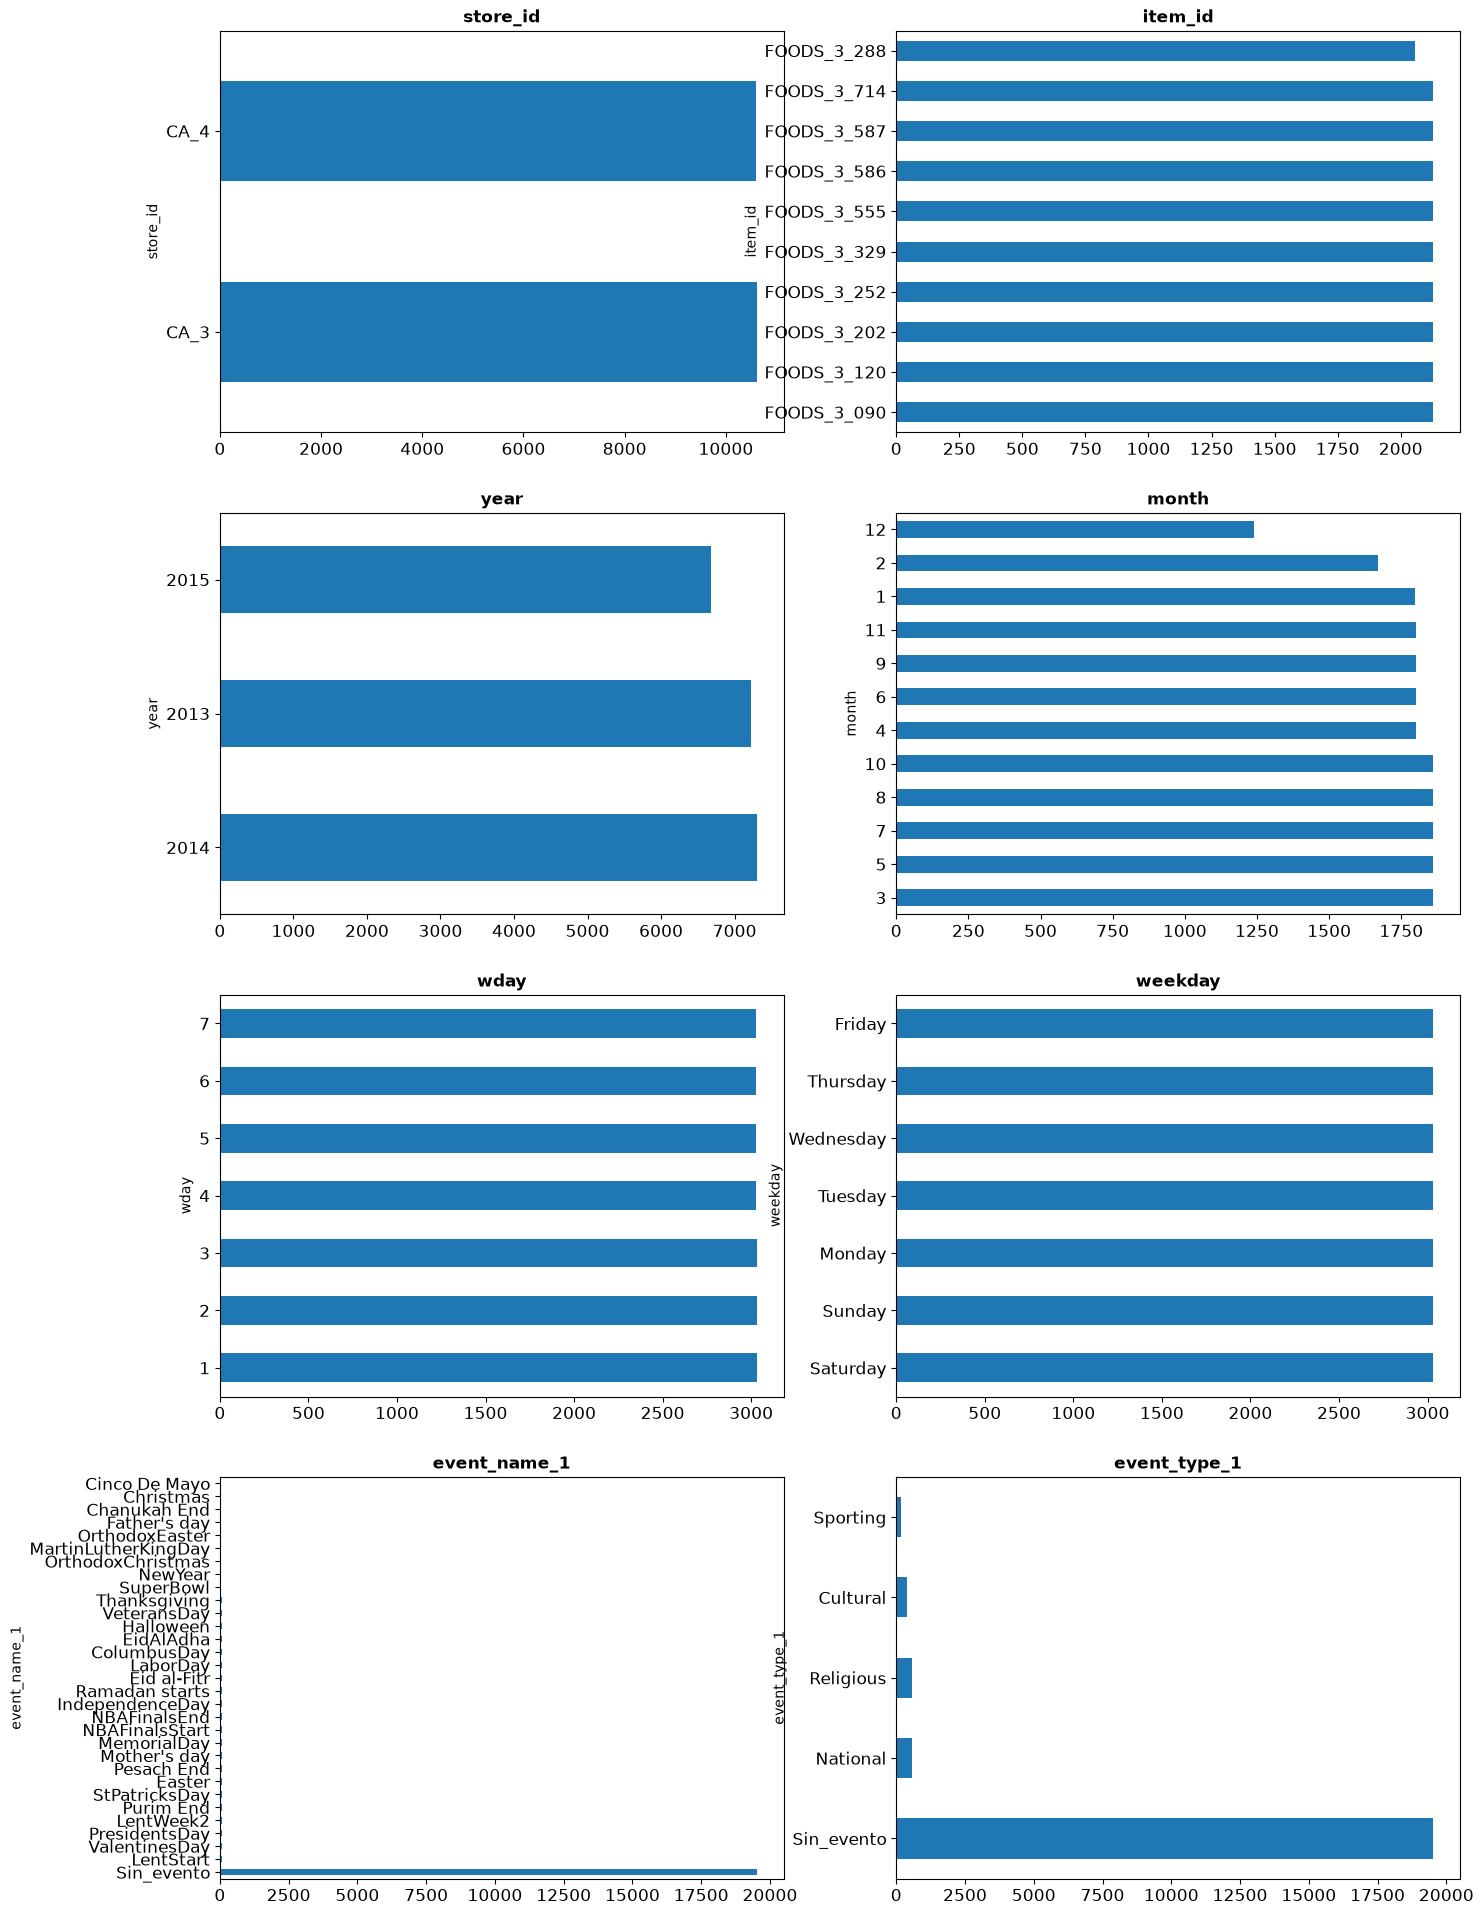

In [34]:
graficos_eda_categoricos(cat[incluir])

## EDA NUMERICAS

### ANALISIS GRAFICO>

In [35]:
df = pd.concat([cat,num],axis=1)
df.head()

,store_id,item_id,dia_ind,year,month,wday,weekday,event_name_1,event_type_1,wm_yr_wk,ventas,sell_price
date,,,,,,,,,,,,
2013-01-01,CA_3,FOODS_3_090,d_704,2013,1,4,Tuesday,NewYear,National,11249,0,1.250
2013-01-01,CA_3,FOODS_3_120,d_704,2013,1,4,Tuesday,NewYear,National,11249,0,4.980
2013-01-01,CA_3,FOODS_3_202,d_704,2013,1,4,Tuesday,NewYear,National,11249,20,4.280
2013-01-01,CA_3,FOODS_3_252,d_704,2013,1,4,Tuesday,NewYear,National,11249,34,1.480
2013-01-01,CA_3,FOODS_3_329,d_704,2013,1,4,Tuesday,NewYear,National,11249,39,2.980


#### Tendencia global de ventas

### Tendencia de las ventas por producto

#### Tendencias de las ventas por tienda y producto